# 기본데이터 타입(stdio.h에서 정의)
> 문자형: char    
> 정수형: int, short, long, long long    
> 실수형: float, double    
> bool형으로 true, false 저장 (stdbool.h에서 정의 by C99 표준)  

# 사용자정의 데이터 타입
> 사용자정의 변수 선언: typedef  

# 복합 데이터 타입 
> 구조체: struct  
> 공용체: union  
> 열거체: enum  
> 구조체는 사용자정의 데이터타입으로 여러 데이터타입을 그룹으로 묶어 활용

# 데이터 타입이 존재하는 이유?
**효율적인 메모리 활용**

## 정수 타입(signed, unsigned)
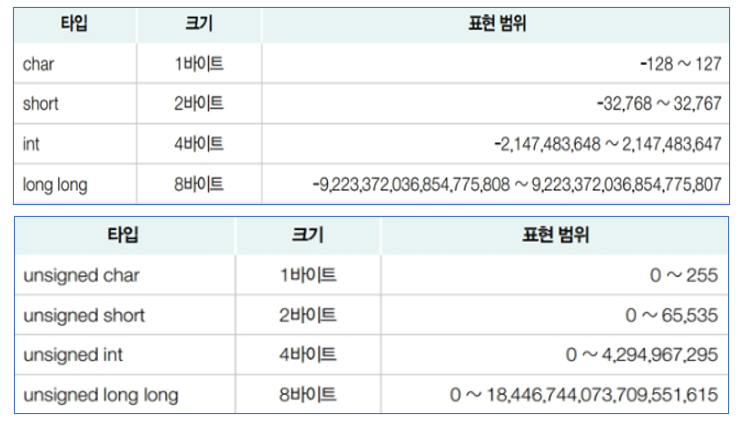

## 정수에서 놓치기 쉬운 오류 
**오버플로우, 언더플로우**  
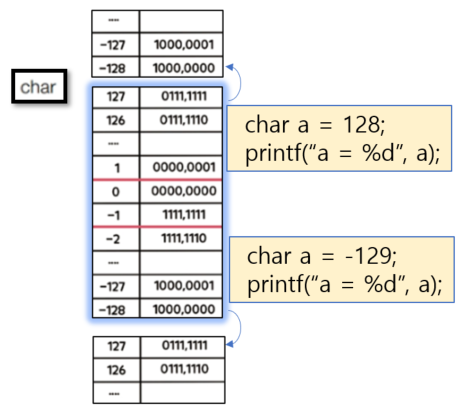

In [ ]:
//오버플로우
char a = 128;
printf("a = %hhd, 비트상태: %hhb", a , a );

In [ ]:
//언더플로우
char a = -129;
printf("a = %hhd, 비트상태: %hhb", a , a);

<div style="background-color:yellow;"> 
    &nbsp;
</div>

## 실수 타입
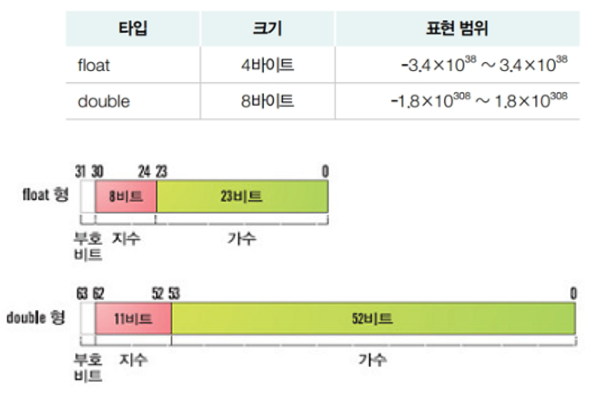  

### 다양한 지수 표기법

<span style="display:inline-block;postion:left;">
    
| C 리터럴    | 수학적 표현     |   실제 값 |
| -------- | ---------- | -----: |
| `1e1`    | 1 × 10¹    |     10 |
| `1e2`    | 1 × 10²    |    100 |
| `1e3`    | 1 × 10³    |  1,000 |
| `1e4`    | 1 × 10⁴    | 10,000 |
| `2e3`    | 2 × 10³    |  2,000 |
| `5e2`    | 5 × 10²    |    500 |
| `1e-1`   | 1 × 10⁻¹   |    0.1 |
| `1e-2`   | 1 × 10⁻²   |   0.01 |
| `1.5e3`  | 1.5 × 10³  |  1,500 |
| `2.5e-3` | 2.5 × 10⁻³ | 0.0025 |  

</span>



## 실수에서 놓치기 쉬운 오류

### ⓐ 정밀도 문제(소수점 이하 자리 손실)

In [ ]:
// 소수점 이하 자리 손실
// float는 소수점이하 8자리까지 유효숫자
// double는 소수점이하 17자리까지 유효숫자
printf("float 연산 결과: %.10f\n", (float)0.123456789);
printf("float 연산 결과: %.10f\n", (float)0.123456781);
printf("double 연산 결과: %.20lf\n", 0.12345678901234567890); //double

### ⓑ 부동소수점 비교 오류

In [ ]:
// 부동소수점 비교 오류
// 실수 비교 시에는 직접 == 사용하지 말고, 오차 범위를 고려해야 함
float a= 0.1f + 0.2f;
if(a == 0.3f) printf("1.같다\n");
else printf("1.다르다\n");
if(a == 0.3) printf("2.같다\n");
else printf("2.다르다\n");
printf("a = %.10f", a);

### ⓒ 정수와 실수의 혼합 연산
* 자동 형변환(정수가 실수로 승격)으로 소수점이하 손실

<span style="position:left;display:inline-block;">
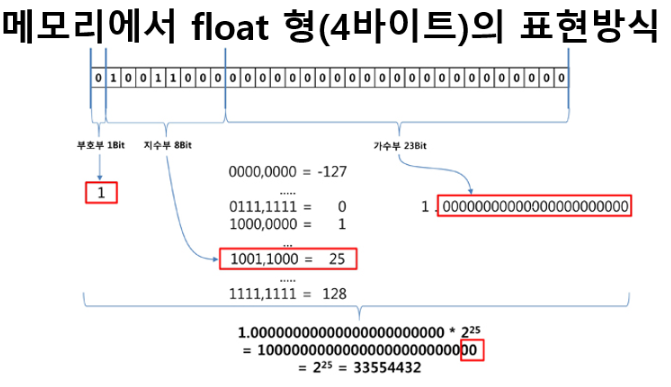
</span>

In [ ]:
// 2^25 --> 정수 표현
printf("2^25 + 0 = %d\n", 0b10000000000000000000000000);
printf("2^25 + 1 = %d\n", 0b10000000000000000000000001);
printf("2^25 + 2 = %d\n", 0b10000000000000000000000010);
printf("2^25 + 3 = %d\n", 0b10000000000000000000000011);
printf("2^25 + 4 = %d\n", 0b10000000000000000000000100);
printf("2^25 + 5 = %d\n", 0b10000000000000000000000101);

In [ ]:
// 2^25 --> 실수 표현
float f1 = 33554432, f2 = 33554433, f3 = 33554434, f4 = 33554435, f5 = 33554436; 
printf("f1 = %.0f\n", f1);
printf("f2 = %.0f\n", f2);
printf("f3 = %.0f\n", f3);
printf("f4 = %.0f\n", f4);
printf("f5 = %.0f\n", f5);

In [ ]:
// 특수값 처리(NaN, Infinity)
// 0으로 나누거나, 정의되지 않은 연산을 하면 NaN(Not a Number) 또는 Infinity 발생
// math.h ==> isnan(), isinf() // 오류 확인시 사용
printf("x = %f\n", 1.0/0.0);
printf("y = %f\n", 0.0/0.0);

In [ ]:
#include <stdio.h>
#include <math.h>
int main(){
    double a = 1.0/0.0;
    double b = 0.0/0.0;

    printf("isinf(a) = %d\n", isinf(a));
    printf("isnan(a) = %d\n", isnan(b));
}

In [ ]:
// 반올림 오차(소수점 유효범위 초과로 인한 손실)
printf("결과 = %.10f", 1.0f/3.0f);

In [ ]:
// 큰수와 작은 수의 연살에서의 손실
double a = 1e20;
double b = 5.0;
double c = a + b;
printf("a + b = %.0lf\n", c);

In [ ]:
// 이 프로그램의 오류를 찾아보라
#include <stdio.h>
int main(){
    int i1=33554434, i2;
    float f;    

    f = i1;
    i2 = f;

    printf("오차: %d - %d = %d",i1, i2, i1 - i2);
}